=== PODEJŚCIE 2: Uproszczone (Train / Test) =====

Wczytywanie danych...
Podział danych zakończony:
  Train:      71608 próbek (wcześniejszy Train + Validation)
  Test:       17903 próbek

Rozpoczynam GridSearchCV na powiększonym zbiorze Train...
Fitting 3 folds for each of 18 candidates, totalling 54 fits
Zakończono w czasie: 266.0s
Najlepsze hiperparametry: {'svm__C': 0.3, 'tfidf__max_features': None, 'tfidf__ngram_range': (1, 3)}
CV F1-macro na X_train: 0.7654

=== WYNIKI FINALNE NA ZBIORZE TEST ===
F1-macro (Test): 0.7768

                precision    recall  f1-score   support

Negative (1-2)       0.78      0.78      0.78      5967
   Neutral (3)       0.70      0.69      0.70      5968
Positive (4-5)       0.85      0.87      0.86      5968

      accuracy                           0.78     17903
     macro avg       0.78      0.78      0.78     17903
  weighted avg       0.78      0.78      0.78     17903



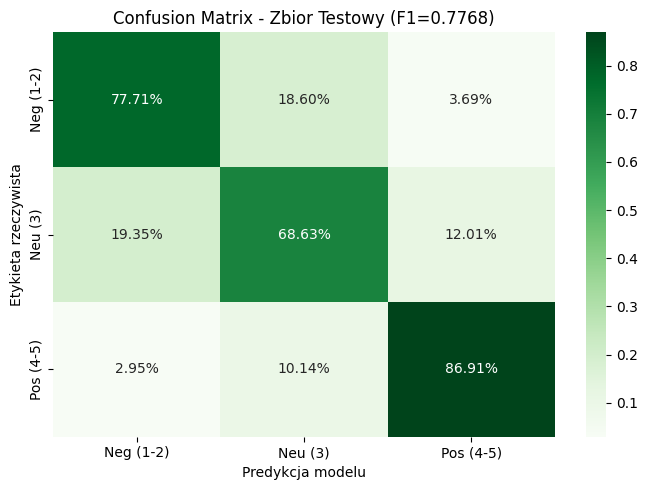

In [1]:
import pandas as pd
import numpy as np
import time
import warnings
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, f1_score, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore')

print("==================================================")
print("=== PODEJŚCIE 2: Uproszczone (Train / Test) =====")
print("==================================================\n")

# 1. Wczytanie danych
print("Wczytywanie danych...")
df = pd.read_csv('data/processed_reviews.csv')
X = df['full_text']
y = df['label']

# 2. Podział na 2 zbiory (Test: 20%, Train: 80%) - brak osobnego Val
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

print(f"Podział danych zakończony:")
print(f"  Train:      {len(X_train)} próbek (wcześniejszy Train + Validation)")
print(f"  Test:       {len(X_test)} próbek\n")

# 3. Definicja Pipeline i GridSearchCV
gs_pipe = Pipeline([
    ('tfidf', TfidfVectorizer(lowercase=True, stop_words=None, min_df=3)),
    ('svm', LinearSVC(max_iter=3000, dual='auto', random_state=42))
])

param_grid = {
    'tfidf__max_features': [15000, 30000, None],
    'tfidf__ngram_range':  [(1, 2), (1, 3)],
    'svm__C':              [0.3, 1, 5],
}

grid_search = GridSearchCV(
    gs_pipe, param_grid, cv=3, scoring='f1_macro', n_jobs=-1, verbose=1, refit=True
)

# 4. Optymalizacja na powiększonym zbiorze Train
print("Rozpoczynam GridSearchCV na powiększonym zbiorze Train...")
start = time.time()
# refit=True automatycznie trenuje najlepszy model na pełnym zbiorze (X_train, y_train) 
# po zakończeniu szukania parametrów w CV
grid_search.fit(X_train, y_train)
print(f"Zakończono w czasie: {time.time() - start:.1f}s")
print(f"Najlepsze hiperparametry: {grid_search.best_params_}")
print(f"CV F1-macro na X_train: {grid_search.best_score_:.4f}\n")

# Uwaga: Nie ma tu manualnego punktu walidacji, ani refitowania (grid_search.fit z refit=True robi to za nas)

# 5. Finalny Test
print("=== WYNIKI FINALNE NA ZBIORZE TEST ===")
best_model = grid_search.best_estimator_

y_test_pred = best_model.predict(X_test)
test_f1 = f1_score(y_test, y_test_pred, average='macro')
print(f"F1-macro (Test): {test_f1:.4f}\n")
print(classification_report(y_test, y_test_pred, target_names=['Negative (1-2)', 'Neutral (3)', 'Positive (4-5)']))

# 6. Confusion Matrix
cm_test = confusion_matrix(y_test, y_test_pred)
cm_test_pct = cm_test.astype(float) / cm_test.sum(axis=1)[:, np.newaxis]

plt.figure(figsize=(7, 5))
sns.heatmap(cm_test_pct, annot=True, fmt='.2%', cmap='Greens',
            xticklabels=['Neg (1-2)', 'Neu (3)', 'Pos (4-5)'],
            yticklabels=['Neg (1-2)', 'Neu (3)', 'Pos (4-5)'])
plt.ylabel('Etykieta rzeczywista')
plt.xlabel('Predykcja modelu')
plt.title(f'Confusion Matrix - Zbior Testowy (F1={test_f1:.4f})')
plt.tight_layout()
plt.show()
